<a href="https://colab.research.google.com/github/scudilio/AI---Deep-Learning/blob/main/Aula%204/MBA_DL_Aula4_01_bert_atencao_e_contexto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 4 | Notebook 0: do Transformer ao BERT, o contexto muda o vetor

### MBA FIAP | Deep Learning e Redes Neurais Modernas | Profa. Juliana Scudilio

**O problema:** Nas três gerações que vimos (sacola de palavras, embeddings, LSTM), a palavra "banco" tem um vetor só, seja no banco da praça ou no banco do empréstimo. O Transformer resolve isso com **atenção**: cada palavra olha para as outras da frase e monta o seu vetor a partir delas.

**O que vamos fazer.**
1. Ver o limite: um vetor por palavra, sem contexto.
2. Calcular a atenção **à mão**, com a fórmula, numa frase de 6 palavras.
3. Usar um Transformer de verdade, o BERT em português (BERTimbau), e ver "banco" ganhar vetores diferentes conforme a frase.
4. Entender tokens, e por que português custa mais que inglês.
5. Aplicação: classificar sentimento com o BERT **congelado** e comparar com o TF-IDF da aula 3, usando poucos dados. É o primeiro degrau de transfer learning em texto; os cases 1 a 4 desta aula partem daqui.

Roda no Google Colab, em CPU (a aplicação leva uns 10 minutos; com GPU, menos de 1). Tempo em aula: 28 min. Precisa de internet para baixar o modelo (400 MB) e de `reviews_b2w_subset.csv` (envie quando o seletor abrir, ou clone o repositório).

## 1. Preparar

In [1]:
%pip install -q "transformers>=4.56"

In [2]:
import os, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(0); np.random.seed(0)
print("torch", torch.__version__, "| GPU?", torch.cuda.is_available())

torch 2.14.1+cu130 | GPU? True


In [3]:
# O modelo: BERTimbau, um BERT treinado em português (Souza, Nogueira e Lotufo, 2020). 109 milhões de parâmetros.
NOME = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(NOME)
bert = AutoModel.from_pretrained(NOME, output_attentions=True)
bert.eval()
print("Camadas:", bert.config.num_hidden_layers, "| cabeças por camada:", bert.config.num_attention_heads, "| tamanho do vetor:", bert.config.hidden_size)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Camadas: 12 | cabeças por camada: 12 | tamanho do vetor: 768


## 2. O limite: uma palavra, um vetor

Antes da atenção, o BERT também tem uma tabela de embeddings: um vetor fixo por token, como o word2vec. Vamos pegar o vetor de "banco" em duas frases e comparar.

In [4]:
frases = ["O banco aprovou o empréstimo.", "Sentei no banco da praça.", "Fui ao banco pagar o boleto."]

def tokens_de(frase):
    return tokenizer.tokenize(frase)

for f in frases:
    print(f"{f:<35} ->", tokens_de(f))

O banco aprovou o empréstimo.       -> ['O', 'banco', 'aprovou', 'o', 'empréstimo', '.']
Sentei no banco da praça.           -> ['Sent', '##ei', 'no', 'banco', 'da', 'praça', '.']
Fui ao banco pagar o boleto.        -> ['Fu', '##i', 'ao', 'banco', 'pagar', 'o', 'bol', '##eto', '.']


In [5]:
tabela = bert.embeddings.word_embeddings.weight.detach()        # a tabela de embeddings estáticos: (vocabulário x 768)

def vetor_estatico(palavra):
    return tabela[tokenizer.convert_tokens_to_ids(palavra)]

def cosseno(a, b):
    return float(torch.dot(a, b) / (a.norm() * b.norm()))

v = vetor_estatico("banco")
print("Vetor estático de 'banco':", v.shape, "| 'banco' (empréstimo) vs 'banco' (praça): cosseno =", round(cosseno(v, v), 3))
print("É o mesmo vetor nas três frases. A tabela não sabe em que frase a palavra está.")

Vetor estático de 'banco': torch.Size([768]) | 'banco' (empréstimo) vs 'banco' (praça): cosseno = 1.0
É o mesmo vetor nas três frases. A tabela não sabe em que frase a palavra está.


## 3. Atenção à mão: a fórmula em 6 palavras

A ideia: cada palavra pergunta às outras "quem é relevante para mim?", recebe uma nota de cada uma, transforma as notas em pesos que somam 1 (softmax) e monta o seu novo vetor como **média ponderada** dos vetores das outras.

```
notas  = Q · Kᵀ / √d          (quanto cada palavra combina com cada outra)
pesos  = softmax(notas)        (uma linha por palavra, soma 1)
saída  = pesos · V             (o novo vetor de cada palavra: mistura das outras)
```

No Transformer, Q, K e V são projeções aprendidas dos embeddings (Q = E·Wq, etc.). Aqui, para ver só a mecânica, usamos os embeddings direto: Q = K = V = E.

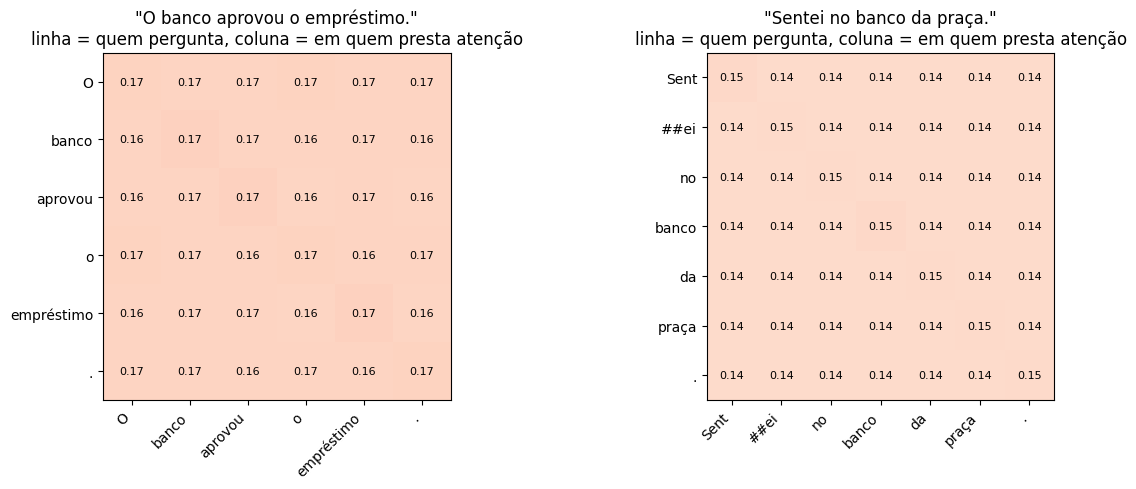

In [6]:
def atencao_a_mao(frase):
    toks = tokens_de(frase)
    E = torch.stack([vetor_estatico(t) for t in toks])            # (n_palavras x 768)
    Q = K = V = E                                                  # sem projeções aprendidas, só a mecânica
    notas = Q @ K.T / math.sqrt(E.shape[1])                        # (n x n)
    pesos = torch.softmax(notas, dim=1)                            # cada linha soma 1
    saida = pesos @ V                                              # (n x 768): o vetor novo de cada palavra
    return toks, pesos, saida

toks1, pesos1, saida1 = atencao_a_mao(frases[0])
toks2, pesos2, saida2 = atencao_a_mao(frases[1])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, toks, pesos, f in zip(axes, [toks1, toks2], [pesos1, pesos2], frases[:2]):
    im = ax.imshow(pesos, cmap="Reds", vmin=0, vmax=1)
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=45, ha="right")
    ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks)
    ax.set_title(f'"{f}"\nlinha = quem pergunta, coluna = em quem presta atenção');
    for i in range(len(toks)):
        for j in range(len(toks)):
            ax.text(j, i, f"{pesos[i, j]:.2f}", ha="center", va="center", fontsize=8, color="black" if pesos[i, j] < 0.6 else "white")
plt.tight_layout(); plt.show()

In [7]:
# A linha de "banco" em cada frase: para onde ela olha?
for toks, pesos, f in [(toks1, pesos1, frases[0]), (toks2, pesos2, frases[1])]:
    i = toks.index("banco")
    print(f'"{f}" -> banco presta atenção em:', {t: round(float(p), 2) for t, p in zip(toks, pesos[i])})

b1 = saida1[toks1.index("banco")]; b2 = saida2[toks2.index("banco")]
print("\nDepois da atenção: cosseno entre os dois vetores de 'banco' =", round(cosseno(b1, b2), 3), "(antes era 1.0)")

"O banco aprovou o empréstimo." -> banco presta atenção em: {'O': 0.16, 'banco': 0.17, 'aprovou': 0.17, 'o': 0.16, 'empréstimo': 0.17, '.': 0.16}
"Sentei no banco da praça." -> banco presta atenção em: {'Sent': 0.14, '##ei': 0.14, 'no': 0.14, 'banco': 0.15, 'da': 0.14, 'praça': 0.14, '.': 0.14}

Depois da atenção: cosseno entre os dois vetores de 'banco' = 0.503 (antes era 1.0)


Repare nos pesos: quase iguais (0,14 a 0,17). Sem projeções aprendidas, a atenção vira uma média simples da frase; mesmo assim o vetor de "banco" já depende das vizinhas (o cosseno deixou de ser 1,0). O que torna a atenção útil são as matrizes **aprendidas** que transformam cada embedding em Q, K e V: elas ensinam o modelo a olhar para as palavras certas.

A célula abaixo repete a mesma fórmula, agora com as matrizes Q e K **reais** da primeira camada do BERT (uma das 12 cabeças). Nada mais muda.

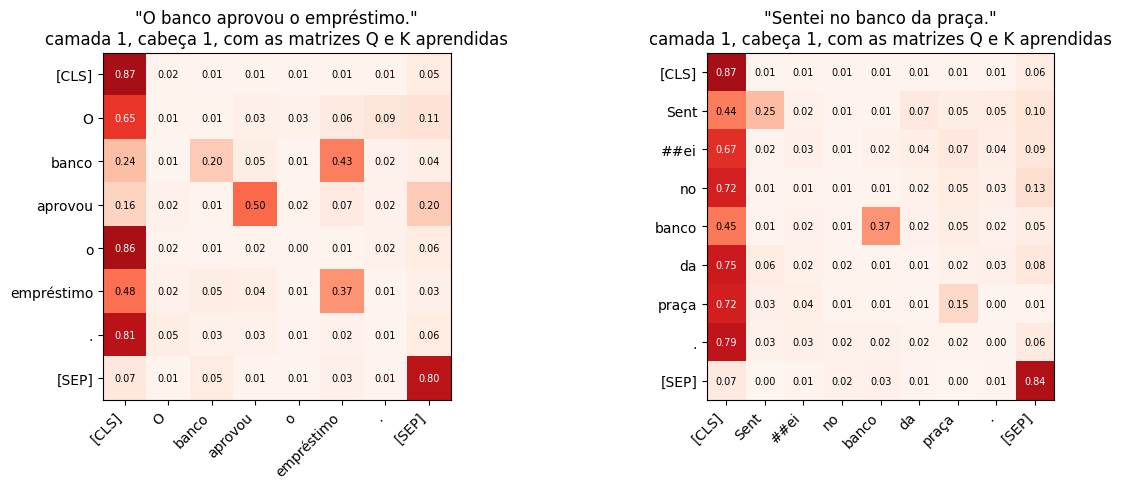

In [8]:
camada0 = bert.encoder.layer[0].attention.self            # a primeira camada de atenção do BERT
D_CABECA = 768 // bert.config.num_attention_heads          # 64 dimensões por cabeça

def atencao_com_pesos_do_bert(frase, cabeca=0):
    entrada = tokenizer(frase, return_tensors="pt")
    toks = tokenizer.convert_ids_to_tokens(entrada["input_ids"][0])
    with torch.no_grad():
        E = bert.embeddings(input_ids=entrada["input_ids"])[0]        # embeddings + posição: o que entra na camada 0
        Q = camada0.query(E)[:, cabeca*D_CABECA:(cabeca+1)*D_CABECA]   # Q = E · Wq  (fatia desta cabeça)
        K = camada0.key(E)[:, cabeca*D_CABECA:(cabeca+1)*D_CABECA]     # K = E · Wk
        pesos = torch.softmax(Q @ K.T / math.sqrt(D_CABECA), dim=1)    # a mesma fórmula de antes
    return toks, pesos

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, f in zip(axes, frases[:2]):
    toks, pesos = atencao_com_pesos_do_bert(f)
    ax.imshow(pesos, cmap="Reds", vmin=0, vmax=1)
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=45, ha="right"); ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks)
    ax.set_title(f'"{f}"\ncamada 1, cabeça 1, com as matrizes Q e K aprendidas')
    for i in range(len(toks)):
        for j in range(len(toks)):
            ax.text(j, i, f"{pesos[i, j]:.2f}", ha="center", va="center", fontsize=7, color="black" if pesos[i, j] < 0.6 else "white")
plt.tight_layout(); plt.show()

Com as matrizes aprendidas, os pesos deixam de ser uniformes: cada cabeça escolhe para onde olhar ([CLS] e [SEP] são tokens especiais de início e fim que o BERT acrescenta). Há 144 mapas como este por frase, um por cabeça e camada.

⏱ **Checkpoint 1:** os mapas apareceram?

## 4. O Transformer de verdade: o vetor de "banco" muda com a frase

Agora passamos as três frases pelo BERT inteiro (12 camadas de atenção, 12 cabeças cada) e pegamos o vetor de "banco" na saída da última camada.

In [9]:
def vetor_contextual(frase, palavra="banco"):
    entrada = tokenizer(frase, return_tensors="pt")
    with torch.no_grad():
        saida = bert(**entrada)
    toks = tokenizer.convert_ids_to_tokens(entrada["input_ids"][0])
    i = toks.index(palavra)
    return saida.last_hidden_state[0, i], saida.attentions, toks

vetores = [vetor_contextual(f)[0] for f in frases]
print("Cosseno entre os vetores contextuais de 'banco':")
print(f"{'':<32}", *[f"frase {j+1:<6}" for j in range(3)])
for i, f in enumerate(frases):
    print(f"{f:<32}", *[f"{cosseno(vetores[i], vetores[j]):>8.3f}" for j in range(3)])
print("\nFrases 1 e 3 (banco = instituição) ficam mais próximas entre si do que da frase 2 (banco = assento).")

Cosseno entre os vetores contextuais de 'banco':
                                 frase 1      frase 2      frase 3     
O banco aprovou o empréstimo.       1.000    0.570    0.798
Sentei no banco da praça.           0.570    1.000    0.687
Fui ao banco pagar o boleto.        0.798    0.687    1.000

Frases 1 e 3 (banco = instituição) ficam mais próximas entre si do que da frase 2 (banco = assento).


O mesmo token, três vetores. É o que nenhuma das três gerações anteriores conseguia: **o contexto entrou no vetor**.

### O mapa de atenção real

Cada uma das 12 camadas tem 12 cabeças, cada uma com um mapa como o que calculamos à mão. Abaixo, a média das cabeças da última camada para a frase 1.

In [ ]:
_, atencoes, toks = vetor_contextual(frases[0])
mapa = atencoes[-1][0].mean(dim=0).numpy()          # última camada, média das 12 cabeças: (n_tokens x n_tokens)

plt.figure(figsize=(7, 6))
plt.imshow(mapa, cmap="Reds", vmin=0, vmax=1)      # mesma escala de cores dos mapas anteriores (0 a 1)
plt.xticks(range(len(toks)), toks, rotation=45, ha="right"); plt.yticks(range(len(toks)), toks)
for i in range(len(toks)):                          # escreve o peso dentro de cada célula
    for j in range(len(toks)):
        plt.text(j, i, f"{mapa[i, j]:.2f}", ha="center", va="center", fontsize=8, color="black" if mapa[i, j] < 0.6 else "white")
plt.title("BERT, última camada, média das 12 cabeças\nlinha = quem olha, coluna = para quem olha; cada linha soma 1")
plt.tight_layout(); plt.show()

# a linha de "banco" em números, para ler em voz alta
i_banco = toks.index("banco")
print("Para onde 'banco' olha na última camada:", {t: round(float(mapa[i_banco, j]), 2) for j, t in enumerate(toks)})
print(f"Soma da linha: {mapa[i_banco].sum():.2f} | peso em [CLS] + [SEP]: {mapa[i_banco, 0] + mapa[i_banco, -1]:.2f}")

⏱ **Checkpoint 2:** a tabela de cossenos mostrou a frase 2 mais distante?

## 5. Tokens: a unidade que o modelo lê (e que a nuvem cobra)

O modelo não lê palavras: lê **tokens**, pedaços de palavra de um vocabulário fixo. Palavras comuns são um token; palavras raras ou longas viram vários (os pedaços começam com `##`). Em português, com conjugações e acentos, uma frase costuma virar mais tokens que a mesma frase em inglês. Nos modelos de linguagem comerciais, o preço é por token.

In [11]:
exemplos = ["O produto chegou rápido e funciona bem.",
            "Entrega atrasada e produto veio quebrado.",
            "Inacreditavelmente desorganizado o atendimento da transportadora."]
for f in exemplos:
    t = tokens_de(f)
    print(f"{len(f.split()):>2} palavras -> {len(t):>2} tokens: {t}")

 7 palavras ->  8 tokens: ['O', 'produto', 'chegou', 'rápido', 'e', 'funciona', 'bem', '.']
 6 palavras ->  9 tokens: ['Entre', '##ga', 'atras', '##ada', 'e', 'produto', 'veio', 'quebrado', '.']
 6 palavras -> 14 tokens: ['In', '##ac', '##red', '##ita', '##velmente', 'des', '##organ', '##izado', 'o', 'atendimento', 'da', 'transpor', '##tadora', '.']


In [12]:
# Português custa mais que inglês? O mesmo texto, no tokenizador de um modelo de linguagem treinado sobretudo em inglês (GPT-2).
tok_en = AutoTokenizer.from_pretrained("gpt2")
pares = [("The delivery was late and the product arrived broken.", "A entrega atrasou e o produto chegou quebrado."),
         ("I loved it, it works perfectly and the price is fair.", "Adorei, funciona perfeitamente e o preço é justo.")]
for en, pt in pares:
    print(f"EN {len(tok_en.tokenize(en)):>2} tokens | PT {len(tok_en.tokenize(pt)):>2} tokens | {pt}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

EN 10 tokens | PT 18 tokens | A entrega atrasou e o produto chegou quebrado.
EN 13 tokens | PT 20 tokens | Adorei, funciona perfeitamente e o preço é justo.


## 6. Aplicação: sentimento com o BERT congelado, com poucos dados

Na aula 3, com 24 mil reviews de treino, o TF-IDF deu 93,9% e a LSTM 92,8%. E com **1.500** reviews?

A receita é a mesma da MobileNetV2 congelada da aula 1: o BERT fica **congelado** e vira um extrator: cada review entra, sai um vetor de 768 números (a média dos vetores dos tokens). Em cima disso, uma regressão logística. Comparamos com um TF-IDF treinado nos mesmos 1.500 reviews e testado nos mesmos 1.000.

In [13]:
# os dados: o mesmo arquivo da aula 3 (reviews B2W). Esta amostra (random_state=0) é reutilizada nos cases 1 e 3.
candidatos = ["reviews_b2w_subset.csv", "../data/reviews_b2w_subset.csv", "data/reviews_b2w_subset.csv"]
caminho = next((c for c in candidatos if os.path.exists(c)), None)
if caminho is None:
    from google.colab import files
    print("Envie o arquivo reviews_b2w_subset.csv:")
    caminho = list(files.upload())[0]

df = pd.read_csv(caminho)
df["review_text"] = df["review_text"].astype(str)
df["y"] = (df["sentimento"] == "positivo").astype(int)

N_TREINO, N_TESTE = 1500, 1000
amostra = df.sample(N_TREINO + N_TESTE, random_state=0)
tr, te = amostra.iloc[:N_TREINO], amostra.iloc[N_TREINO:]
print("treino", len(tr), "| teste", len(te), "| positivos no treino:", f"{tr['y'].mean():.0%}")

Envie o arquivo reviews_b2w_subset.csv:


Saving reviews_b2w_subset.csv to reviews_b2w_subset.csv
treino 1500 | teste 1000 | positivos no treino: 50%


In [ ]:
def vetores_bert(textos, lote=32, max_tokens=64):
    """Passa os textos pelo BERT congelado e devolve um vetor de 768 números por texto (média dos tokens)."""
    saidas = []
    with torch.no_grad():
        for i in range(0, len(textos), lote):
            b = tokenizer(textos[i:i+lote], padding=True, truncation=True, max_length=max_tokens, return_tensors="pt")
            h = bert(**b).last_hidden_state                              # (lote x tokens x 768)
            mascara = b["attention_mask"].unsqueeze(-1)                  # ignora o preenchimento
            saidas.append(((h * mascara).sum(1) / mascara.sum(1)).numpy())
    return np.vstack(saidas)

t0 = time.time()
Xtr_bert = vetores_bert(tr["review_text"].tolist())
Xte_bert = vetores_bert(te["review_text"].tolist())
print("Vetores:", Xtr_bert.shape, Xte_bert.shape, f"| tempo: {time.time()-t0:.0f} s")

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score

# BERT congelado + regressão logística
clf_bert = LogisticRegression(max_iter=2000).fit(Xtr_bert, tr["y"])
acc_bert = accuracy_score(te["y"], clf_bert.predict(Xte_bert))

# TF-IDF + regressão logística, nos mesmos 1.500 reviews
tfidf = TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)
clf_tfidf = LogisticRegression(max_iter=2000).fit(tfidf.fit_transform(tr["review_text"]), tr["y"])
acc_tfidf = accuracy_score(te["y"], clf_tfidf.predict(tfidf.transform(te["review_text"])))

print(f"{'Abordagem':<42} {'reviews de treino':>18} {'acurácia teste':>15}")
print(f"{'TF-IDF + regressão logística':<42} {N_TREINO:>18} {acc_tfidf*100:>14.1f}%")
print(f"{'BERT congelado + regressão logística':<42} {N_TREINO:>18} {acc_bert*100:>14.1f}%")
print(f"{'(aula 3, 24 mil) TF-IDF + regressão logística':<42} {24000:>18} {'93.9%':>15}")
print(f"{'(aula 3, 24 mil) LSTM com embedding':<42} {24000:>18} {'92.8%':>15}")

In [ ]:
# frases novas: as duas abordagens lado a lado
novas = ["Chegou antes do prazo e o produto é excelente.",
         "Não recomendo, veio com defeito e ninguém responde.",
         "Esperava mais pelo preço, mas cumpre o que promete.",
         "Produto bom, entrega péssima."]
p_bert = clf_bert.predict_proba(vetores_bert(novas))[:, 1]
p_tfidf = clf_tfidf.predict_proba(tfidf.transform(novas))[:, 1]
for f, a, b in zip(novas, p_tfidf, p_bert):
    print(f"TF-IDF {a:.2f} | BERT {b:.2f} | {f}")
print("\n(probabilidade de ser positivo; troque as frases e teste as suas)")

⏱ **Checkpoint 3:** qual foi a acurácia do BERT congelado na sua execução?

## O que acabou de acontecer

| | Sacola / TF-IDF | Embeddings + LSTM | Transformer (BERT) |
|---|---|---|---|
| O que vê | Quais palavras aparecem | Palavras parecidas têm vetores parecidos; lê na ordem | Cada palavra olha para as outras: o contexto entra no vetor |
| "banco" | Uma coluna | Um vetor | Um vetor por frase |
| Precisa de dados rotulados | Muitos | Muitos | Poucos, porque o pré-treino já pagou a conta |
| Custo | Segundos em CPU | Minutos em CPU | Minutos em CPU congelado; GPU para ajustar |

**O que levar:** atenção é uma média ponderada em que os pesos são aprendidos. Empilhar 12 camadas disso, treinar em bilhões de palavras e você tem o BERT; trocar o encoder por um decoder que prevê a próxima palavra e você tem o GPT. Os quatro cases desta aula mostram como **adaptar** um modelo assim ao seu negócio: prompt, RAG, LoRA e CLIP.

## Para discutir

1. O BERT congelado com 1.500 reviews chegou perto do TF-IDF com 24 mil (aula 3). O que isso muda no custo de rotular dados na sua empresa?
2. Onde, no seu negócio, a mesma palavra muda de sentido conforme o contexto (e um filtro por palavra-chave erra)?
3. Por que o preço por token torna o português mais caro, e o que fazer a respeito (encurtar prompts, resumir antes, escolher o modelo)?